# Flood hazard, disruption scenarios and road vulnerability (CLIMADA)

| manuscript | figure file | what |
|---|---|---|
| Main text, `fig:scenarios`, panel (b) | `fig_multibasin_cambodia_merged.png` (lower part) | the three disruption scenarios on the hydro-basin map. Panel (a) of that figure is a hand-drawn timing schematic. |
| Supplementary, `fig:si_case` | `cambodia_basins_rivers_roads.png` | hydro-regions + main rivers, and the OSM road network |
| Supplementary, `fig:si_vuln` | `jrc_vulnerability_function_roads.png` | JRC depth–damage function for roads (Asia) |
| Supplementary, `fig:si_direct` | `fig_direct_impacts.png` | flood depth and damaged roads, 2023-09-27 forecast |

**Data** (`data/climada/`): CLIMADA flood-hazard forecasts (`flood_hazard-2023/*.hdf5`),
HydroBASINS level-6 hydro-regions (`hydrobasin_l6_merge_khm.geojson`), HydroRIVERS v10 (`HydroRIVERS_v10_as.gdb`), OSM roads (`roads_edges_osm.geojson`); plus the disrupted road network in `data/reference/`.

**Environment**: `climada_env` conda env (CLIMADA, rasterio, geopandas, contextily). The maps download basemap tiles, so they need internet.

In [1]:
import os
from pathlib import Path

FIGDIR = Path("figures/generated")
FIGDIR.mkdir(parents=True, exist_ok=True)

import contextily as ctx
ctx.tile.USER_AGENT = "DisruptSC-Cambodia-paper-figures/1.0 (research reproducibility notebooks)"

## Setup and data

In [2]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import contextily as ctx
import rasterio
from rasterio.transform import from_origin
from shapely.ops import unary_union
from shapely.geometry import Point
from climada.hazard.base import Hazard
import warnings
warnings.filterwarnings('ignore')

/Users/elisanobile/miniforge3/envs/climada_env/lib/python3.11/site-packages/dask/dataframe/_pyarrow_compat.py:15: FutureWarning: Minimal version of pyarrow will soon be increased to 14.0.1. You are using 12.0.1. Please consider upgrading.
  warnings.warn(


In [3]:
# Configuration
HAZARD_DIR = "data/climada/flood_hazard-2023"
ROAD_FILE = "data/reference/roads_with_disruptions.geojson"
BASIN_FILE = "data/climada/hydrobasin_l6_merge_khm.geojson"
OUTPUT_DIR = "figures/generated"
TIF_DIR = "data/climada/flood_maps"
FIGURE_DIR = OUTPUT_DIR

os.makedirs(TIF_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)

In [4]:
SCENARIOS = {
    'scenario_1': {'file': 'hazard_flood_2023-09-27.hdf5', 'title': 'Flood Forecast - 2023-09-27'},
    'scenario_2': {'file': 'hazard_flood_2023-09-19.hdf5', 'title': 'Flood Forecast - 2023-09-19'},
    'scenario_3': {'file': 'hazard_flood_2023-10-13.hdf5', 'title': 'Flood Forecast - 2023-10-13'}
}

#### this were the initial flood hazard maps adopted as representative flood scenarios - the simulation then was done only for the first scenario. the reason was that although the maximum intensity is higher - the event was not spread country-wide (and this is also checked against official UNDRR records). the two other events are either too large or too little and it is very difficult to catch significant patterns.

In [5]:
def get_flood_colormap():
    boundaries = [0, 0.1, 0.5, 1, 2, 3, 5, 10, 20, 30]
    colors = ['#e6f7ff', '#b3e6ff', '#66ccff', '#1aa3ff', '#0080ff', 
              '#0066cc', '#ff9900', '#ff6600', '#ff0000']
    return mcolors.ListedColormap(colors), mcolors.BoundaryNorm(boundaries, len(colors)), boundaries

In [6]:
def load_and_process_hazard(scenario_name):
    hazard_path = os.path.join(HAZARD_DIR, SCENARIOS[scenario_name]['file'])
    hazard = Hazard.from_hdf5(hazard_path)
    intensity_values = hazard.intensity[0, :].toarray().flatten()
    
    # Create raster
    lats = np.sort(np.unique(hazard.centroids.lat))
    lons = np.sort(np.unique(hazard.centroids.lon))
    raster = np.zeros((len(lats), len(lons)), dtype=np.float32)
    
    for lat, lon, intensity in zip(hazard.centroids.lat, hazard.centroids.lon, intensity_values):
        if intensity > 0:
            lat_idx = np.searchsorted(lats, lat)
            lon_idx = np.searchsorted(lons, lon)
            if lat_idx < len(lats) and lon_idx < len(lons):
                raster[lat_idx, lon_idx] = intensity
    
    # Save as GeoTIFF
    pixel_size = 0.1
    transform = from_origin(lons.min() - pixel_size/2, lats.max() + pixel_size/2, pixel_size, pixel_size)
    
    tif_path = os.path.join(TIF_DIR, f'{scenario_name}_flood_depth.tif')
    with rasterio.open(tif_path, 'w', driver='GTiff', height=raster.shape[0], width=raster.shape[1],
                       count=1, dtype=raster.dtype, crs='EPSG:4326', transform=transform) as dst:
        dst.write(raster, 1)
    
    return hazard, intensity_values, raster, (lats, lons)

In [7]:
def create_flood_raster(hazard, intensity_values, basin_union):
    lats = np.sort(np.unique(hazard.centroids.lat))
    lons = np.sort(np.unique(hazard.centroids.lon))
    raster = np.full((len(lats), len(lons)), np.nan, dtype=np.float32)
    
    mask = intensity_values > 0
    if np.any(mask):
        flood_coords = list(zip(hazard.centroids.lat[mask], hazard.centroids.lon[mask], intensity_values[mask]))
        
        for lat, lon, intensity in flood_coords:
            if basin_union.contains(Point(lon, lat)):
                lat_idx = np.searchsorted(lats, lat)
                lon_idx = np.searchsorted(lons, lon)
                if lat_idx < len(lats) and lon_idx < len(lons):
                    raster[lat_idx, lon_idx] = intensity
    
    return raster, (lons.min(), lons.max(), lats.min(), lats.max())

In [8]:
def plot_scenario(ax, scenario_name, hazards_data, roads_gdf, basins_gdf, basin_union, plot_type='combined', show_disruption=True):
    hazard, intensity_values = hazards_data[scenario_name]
    scenario_info = SCENARIOS[scenario_name]
    
    # Set map bounds
    bounds = basins_gdf.total_bounds
    margin = 0.05 * max(bounds[2] - bounds[0], bounds[3] - bounds[1])
    ax.set_xlim(bounds[0] - margin, bounds[2] + margin)
    ax.set_ylim(bounds[1] - margin, bounds[3] + margin)
    
    # Add basemap
    try:
        ctx.add_basemap(ax, crs='EPSG:4326', source=ctx.providers.OpenStreetMap.Mapnik, zoom='auto', alpha=0.5)
    except:
        pass
    
    flood_im = None
    if plot_type in ['flood', 'combined']:
        # Plot flood depths
        cmap, norm, boundaries = get_flood_colormap()
        raster, extent = create_flood_raster(hazard, intensity_values, basin_union)
        flood_im = ax.imshow(raster, extent=extent, origin='lower', cmap=cmap, norm=norm, alpha=0.7)
    
    if plot_type in ['roads', 'combined']:
        # Plot roads
        impact_col = f'impact_{scenario_name}'
        if impact_col in roads_gdf.columns:
            if show_disruption:
                roads_gdf[roads_gdf[impact_col] == 'none'].plot(ax=ax, color='black', linewidth=0.8, alpha=0.9)
                roads_gdf[roads_gdf[impact_col] == 'disruption'].plot(ax=ax, color='#0066ff', linewidth=1.2, alpha=0.9)
                roads_gdf[roads_gdf[impact_col] == 'damage'].plot(ax=ax, color='#ff3300', linewidth=1.5, alpha=1.0)
            else:
                no_damage_roads = roads_gdf[(roads_gdf[impact_col] == 'none') | (roads_gdf[impact_col] == 'disruption')]
                damage_roads = roads_gdf[roads_gdf[impact_col] == 'damage']
                no_damage_roads.plot(ax=ax, color='black', linewidth=0.8, alpha=0.9)
                damage_roads.plot(ax=ax, color='#ff3300', linewidth=1.5, alpha=1.0)
    
    # Plot basins
    basins_gdf.boundary.plot(ax=ax, color='darkgreen', linewidth=1.5, alpha=0.9)
    
    # Add basin labels
    if 'SUB_NAME' in basins_gdf.columns:
        for _, row in basins_gdf.iterrows():
            centroid = row.geometry.centroid
            ax.annotate(row['SUB_NAME'], xy=(centroid.x, centroid.y), fontsize=9, fontweight='bold',
                       ha='center', va='center', bbox=dict(boxstyle='round,pad=0.3', facecolor='white', 
                                                          edgecolor='darkgreen', alpha=0.8))
    
    ax.set_title(scenario_info['title'], fontsize=12, fontweight='bold')
    ax.set_xlabel('Longitude', fontsize=10)
    ax.set_ylabel('Latitude', fontsize=10)
    
    return flood_im

In [9]:
def create_plots(hazards_data, roads_gdf, basins_gdf, plot_type='combined', show_disruption=True):
    fig, axes = plt.subplots(1, 3, figsize=(24, 8))
    basin_union = unary_union(basins_gdf.geometry.values)
    
    flood_ims = []
    for i, scenario_name in enumerate(SCENARIOS.keys()):
        flood_im = plot_scenario(axes[i], scenario_name, hazards_data, roads_gdf, basins_gdf, basin_union, plot_type, show_disruption)
        if flood_im:
            flood_ims.append(flood_im)
    
    # Title and layout
    titles = {'flood': 'Flood footprint', 'roads': 'Flood impacts', 'combined': 'Flood impacts'}
    fig.suptitle(f'Cambodia Flooding - {titles[plot_type]}', fontsize=16, fontweight='bold', y=0.95)
    
    # Add colorbar for flood plots
    if flood_ims:
        cmap, norm, boundaries = get_flood_colormap()
        cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
        cbar = fig.colorbar(flood_ims[0], cax=cbar_ax, norm=norm)
        cbar.set_label('Flood Depth (m)', fontsize=12, fontweight='bold')
        cbar.set_ticks(boundaries[::2])
    
    # Add legend for road plots
    if plot_type in ['roads', 'combined']:
        from matplotlib.lines import Line2D
        if show_disruption:
            legend_elements = [
                Line2D([0], [0], color='black', lw=2, label='Roads (no damage)'),
                Line2D([0], [0], color='#0066ff', lw=2, label='Roads (disruption)'),
                Line2D([0], [0], color='#ff3300', lw=3, label='Roads (damage)'),
                Line2D([0], [0], color='darkgreen', lw=2, label='Basin boundaries')
            ]
        else:
            legend_elements = [
                Line2D([0], [0], color='black', lw=2, label='Roads (no damage)'),
                Line2D([0], [0], color='#ff3300', lw=3, label='Roads (damage)'),
                Line2D([0], [0], color='darkgreen', lw=2, label='Basin boundaries')
            ]
        fig.legend(handles=legend_elements, loc='center left', bbox_to_anchor=(0.01, 0.5), 
                  fontsize=12, title='Legend', framealpha=0.9)
    
    plt.tight_layout()
    adj_params = {'right': 0.9, 'top': 0.9}
    if plot_type in ['roads', 'combined']:
        adj_params['left'] = 0.12
    plt.subplots_adjust(**adj_params)
    
    # Save
    disruption_suffix = "_with_disruption" if show_disruption else "_damage_only"
    output_path = os.path.join(FIGURE_DIR, f'cambodia_{plot_type}_scenarios{disruption_suffix}.png')
    plt.savefig(output_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"Plot saved: {output_path}")
    
    plt.show()
    return fig

In [10]:
# Load data
roads_gdf = gpd.read_file(ROAD_FILE)
basins_gdf = gpd.read_file(BASIN_FILE)

# Process all scenarios*
hazards_data = {}
for scenario_name in SCENARIOS.keys():
    hazard, intensity_values, _, _ = load_and_process_hazard(scenario_name)
    hazards_data[scenario_name] = (hazard, intensity_values)
    print(f"Processed {scenario_name}: max intensity {intensity_values.max():.2f}m")

Processed scenario_1: max intensity 20.32m
Processed scenario_2: max intensity 10.71m
Processed scenario_3: max intensity 13.51m


## Flood Scenarios Panel

In [11]:
def create_basin_color_plots(basins_gdf):
    """
    Create three subplots with different coloring schemes for basin polygons.
    
    Subplot 1: Single basin disruption - different colors for each target basin
    Subplot 2: Simultaneous multi-basin disruptions - same color for all target basins  
    Subplot 3: Cascading multi-basin disruptions - different warm colors with T0, T1, T2 labels
    """
    
    fig, axes = plt.subplots(1, 3, figsize=(28, 10))
    
    # Target basin names
    target_basins = ['Siem Bok (Mekong)', 'St. Sen (Tonlè Sap)', 'Saigon']
    
    # Check which basins exist in the data
    available_basins = basins_gdf['SUB_NAME'].unique()
    print("Available basin names:", available_basins)
    
    # Set consistent bounds for all subplots
    bounds = basins_gdf.total_bounds
    margin = 0.05 * max(bounds[2] - bounds[0], bounds[3] - bounds[1])
    
    for ax in axes:
        ax.set_xlim(bounds[0] - margin, bounds[2] + margin)
        ax.set_ylim(bounds[1] - margin, bounds[3] + margin)
        
        # Add basemap
        try:
            ctx.add_basemap(ax, crs='EPSG:4326', source=ctx.providers.OpenStreetMap.Mapnik, zoom='auto', alpha=0.3)
        except:
            pass
    
    target_mask = basins_gdf['SUB_NAME'].isin(target_basins)
    
    # Subplot 1: Single basin disruption - Different colors for each target basin
    colors_1 = {'Siem Bok (Mekong)': '#DC267F', 'St. Sen (Tonlè Sap)': '#648FFF', 'Saigon': '#FFB000'}
    
    # Plot non-target basins first
    basins_gdf[~target_mask].plot(ax=axes[0], facecolor='none', edgecolor='gray', linewidth=1.5, alpha=0.7)
    
    # Plot target basins with specific colors
    for basin_name, color in colors_1.items():
        basin_data = basins_gdf[basins_gdf['SUB_NAME'] == basin_name]
        if not basin_data.empty:
            basin_data.plot(ax=axes[0], color=color, alpha=0.7, edgecolor='gray', linewidth=2)

    # Add labels
    for _, row in basins_gdf.iterrows():
        centroid = row.geometry.centroid
        axes[0].annotate(row['SUB_NAME'], xy=(centroid.x, centroid.y), fontsize=24,
                        ha='center', va='center', bbox=dict(boxstyle='round,pad=0.3', facecolor='white', 
                                                           edgecolor='gray', alpha=0.85, linewidth=1.5))

    axes[0].set_title('Single basin disruption', fontsize=30, fontweight='bold', pad=12)
    
    # Subplot 2: Simultaneous multi-basin disruptions - Same color for all target basins
    basins_gdf[target_mask].plot(ax=axes[1], color='#44AA99', alpha=0.6, edgecolor='gray', linewidth=2)
    basins_gdf[~target_mask].plot(ax=axes[1], facecolor='none', edgecolor='gray', linewidth=1.5, alpha=0.7)
    
    # Add labels
    for _, row in basins_gdf.iterrows():
        centroid = row.geometry.centroid
        axes[1].annotate(row['SUB_NAME'], xy=(centroid.x, centroid.y), fontsize=24,
                        ha='center', va='center', bbox=dict(boxstyle='round,pad=0.3', facecolor='white', 
                                                           edgecolor='gray', alpha=0.85, linewidth=1.5))
    
    axes[1].set_title('Simultaneous multi-basin disruptions', fontsize=30, fontweight='bold', pad=12)
    
    # Subplot 3: Cascading multi-basin disruptions - Different warm colors with timing labels
    colors_3 = {
        'Saigon': '#CC6677',           # T0
        'Siem Bok (Mekong)': '#AA4499', # T1
        'St. Sen (Tonlè Sap)': '#882255' # T2
    }
    
    # Timing labels for cascading scenario
    timing_labels = {
        'Saigon': 'H1',
        'Siem Bok (Mekong)': 'H2', 
        'St. Sen (Tonlè Sap)': 'H3'
    }
    
    # Plot non-target basins first
    basins_gdf[~target_mask].plot(ax=axes[2], facecolor='none', edgecolor='gray', linewidth=1.5, alpha=0.7)
    
    # Plot target basins with warm colors
    for basin_name, color in colors_3.items():
        basin_data = basins_gdf[basins_gdf['SUB_NAME'] == basin_name]
        if not basin_data.empty:
            basin_data.plot(ax=axes[2], color=color, alpha=0.8, edgecolor='gray', linewidth=2)
    
    # Add labels with timing for subplot 3
    for _, row in basins_gdf.iterrows():
        centroid = row.geometry.centroid
        basin_name = row['SUB_NAME']
        
        if basin_name in timing_labels:
            # Add basin name
            axes[2].annotate(basin_name, xy=(centroid.x, centroid.y), fontsize=24,
                            ha='center', va='center', bbox=dict(boxstyle='round,pad=0.3', facecolor='white', 
                                                               edgecolor='gray', alpha=0.85, linewidth=1.5))
            
            # Add timing label below basin name
            timing_label = timing_labels[basin_name]
            axes[2].annotate(timing_label, xy=(centroid.x, centroid.y - 0.35), fontsize=24, fontweight='bold',
                            ha='center', va='center', bbox=dict(boxstyle='round,pad=0.2', facecolor='lightyellow', 
                                                               edgecolor='gray', alpha=0.95, linewidth=1.5))
        else:
            # Regular label for non-target basins
            axes[2].annotate(basin_name, xy=(centroid.x, centroid.y), fontsize=24,
                            ha='center', va='center', bbox=dict(boxstyle='round,pad=0.3', facecolor='white', 
                                                               edgecolor='gray', alpha=0.85, linewidth=1.5))
    
    axes[2].set_title('Compound multi-basin disruptions', fontsize=30, fontweight='bold', pad=12)
    
    # Set axis labels
    for ax in axes:
        ax.set_xlabel('Longitude', fontsize=20)
        ax.set_ylabel('Latitude', fontsize=20)
        ax.tick_params(axis='both', labelsize=16)
    
    plt.tight_layout()
    plt.subplots_adjust(top=0.92)
    
    # Save figure
    output_path = os.path.join(FIGURE_DIR, 'cambodia_basin_color_schemes.png')
    plt.savefig(output_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"Basin color plots saved: {output_path}")
    
    plt.show()
    return fig

Available basin names: ['Se Kong (Tonlè San)' 'St. Sen (Tonlè Sap)' 'Saigon' 'Stoeng Chhay Areng'
 'Siem Bok (Mekong)']
Basin color plots saved: figures/generated/cambodia_basin_color_schemes.png


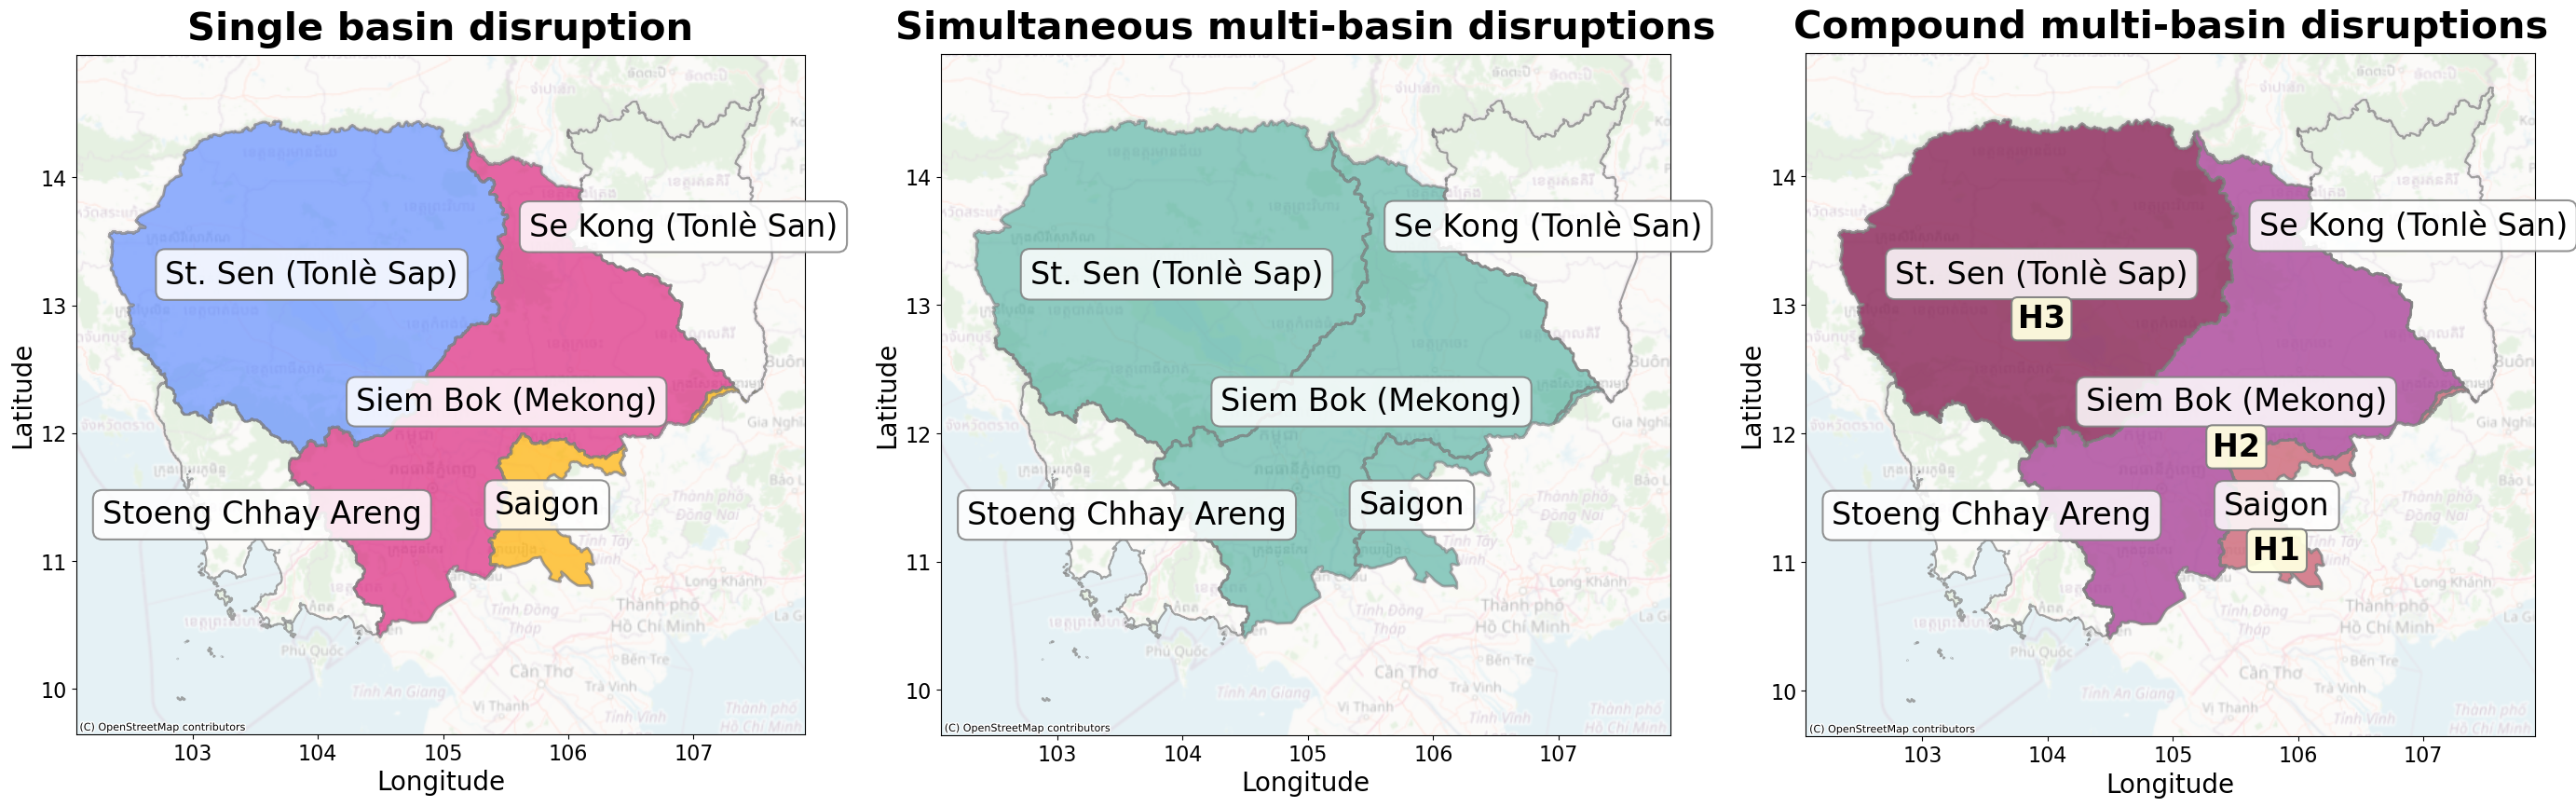

In [12]:
# Create the basin color scheme plots
fig_basin_colors = create_basin_color_plots(basins_gdf)
fig_basin_colors.savefig(FIGDIR / 'fig_multibasin_cambodia_merged_panel_b.png', dpi=300, bbox_inches='tight')

## Direct Impacts Simulation

In [13]:
def create_single_plot(hazards_data, roads_gdf, basins_gdf, scenario_name='scenario_1', plot_type='combined', show_disruption=False):
    """
    Create a single plot for a specific scenario (similar to create_plots but for one scenario only).
    
    Parameters:
    - hazards_data: Dictionary of processed hazard data
    - roads_gdf: GeoDataFrame with road network
    - basins_gdf: GeoDataFrame with basin boundaries  
    - scenario_name: Key from SCENARIOS dict (default: 'scenario_1')
    - plot_type: 'flood', 'roads', or 'combined' (default: 'combined')
    - show_disruption: Whether to show disruption category (default: False)
    """
    from matplotlib.lines import Line2D
    
    fig, ax = plt.subplots(1, 1, figsize=(12, 10))
    basin_union = unary_union(basins_gdf.geometry.values)
    
    hazard, intensity_values = hazards_data[scenario_name]
    scenario_info = SCENARIOS[scenario_name]
    
    # Set map bounds
    bounds = basins_gdf.total_bounds
    margin = 0.05 * max(bounds[2] - bounds[0], bounds[3] - bounds[1])
    ax.set_xlim(bounds[0] - margin, bounds[2] + margin)
    ax.set_ylim(bounds[1] - margin, bounds[3] + margin)
    
    # Add basemap
    try:
        ctx.add_basemap(ax, crs='EPSG:4326', source=ctx.providers.OpenStreetMap.Mapnik, zoom='auto', alpha=0.5)
    except:
        pass
    
    flood_im = None
    if plot_type in ['flood', 'combined']:
        # Plot flood depths
        cmap, norm, boundaries = get_flood_colormap()
        raster, extent = create_flood_raster(hazard, intensity_values, basin_union)
        flood_im = ax.imshow(raster, extent=extent, origin='lower', cmap=cmap, norm=norm, alpha=0.7)
    
    if plot_type in ['roads', 'combined']:
        # Plot roads
        impact_col = f'impact_{scenario_name}'
        if impact_col in roads_gdf.columns:
            if show_disruption:
                roads_gdf[roads_gdf[impact_col] == 'none'].plot(ax=ax, color='black', linewidth=0.8, alpha=0.9)
                roads_gdf[roads_gdf[impact_col] == 'disruption'].plot(ax=ax, color='#0066ff', linewidth=1.2, alpha=0.9)
                roads_gdf[roads_gdf[impact_col] == 'damage'].plot(ax=ax, color='#ff3300', linewidth=1.5, alpha=1.0)
            else:
                no_damage_roads = roads_gdf[(roads_gdf[impact_col] == 'none') | (roads_gdf[impact_col] == 'disruption')]
                damage_roads = roads_gdf[roads_gdf[impact_col] == 'damage']
                no_damage_roads.plot(ax=ax, color='black', linewidth=0.8, alpha=0.9)
                damage_roads.plot(ax=ax, color='#ff3300', linewidth=1.5, alpha=1.0)
    
    # Plot basins
    basins_gdf.boundary.plot(ax=ax, color='darkgreen', linewidth=1.5, alpha=0.9)
    
    # Add basin labels
    if 'SUB_NAME' in basins_gdf.columns:
        for _, row in basins_gdf.iterrows():
            centroid = row.geometry.centroid
            ax.annotate(row['SUB_NAME'], xy=(centroid.x, centroid.y), fontsize=9, fontweight='bold',
                       ha='center', va='center', bbox=dict(boxstyle='round,pad=0.3', facecolor='white', 
                                                          edgecolor='darkgreen', alpha=0.8))
    
    ax.set_title(scenario_info['title'], fontsize=14, fontweight='bold')
    ax.set_xlabel('Longitude', fontsize=11)
    ax.set_ylabel('Latitude', fontsize=11)
    
    # Add colorbar for flood plots
    if flood_im:
        cmap, norm, boundaries = get_flood_colormap()
        cbar = plt.colorbar(flood_im, ax=ax, fraction=0.046, pad=0.04)
        cbar.set_label('Flood Depth (m)', fontsize=11, fontweight='bold')
        cbar.set_ticks(boundaries[::2])
    
    # Add legend for road plots
    if plot_type in ['roads', 'combined']:
        if show_disruption:
            legend_elements = [
                Line2D([0], [0], color='black', lw=2, label='Roads (no damage)'),
                Line2D([0], [0], color='#0066ff', lw=2, label='Roads (disruption)'),
                Line2D([0], [0], color='#ff3300', lw=3, label='Roads (damage)'),
                Line2D([0], [0], color='darkgreen', lw=2, label='Basin boundaries')
            ]
        else:
            legend_elements = [
                Line2D([0], [0], color='black', lw=2, label='Roads (no damage)'),
                Line2D([0], [0], color='#ff3300', lw=3, label='Roads (damage)'),
                Line2D([0], [0], color='darkgreen', lw=2, label='Basin boundaries')
            ]
        ax.legend(handles=legend_elements, loc='upper left', fontsize=10, title='Legend', framealpha=0.9)
    
    plt.tight_layout()
    
    # Save
    disruption_suffix = "_with_disruption" if show_disruption else "_damage_only"
    scenario_date = scenario_info['title'].split(' - ')[-1].replace('-', '_')
    output_path = os.path.join(FIGURE_DIR, f'cambodia_{plot_type}_single_{scenario_date}{disruption_suffix}.png')
    plt.savefig(output_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"Plot saved: {output_path}")
    
    plt.show()
    return fig

Processed scenario_1: max intensity 20.32m
Plot saved: figures/generated/cambodia_combined_single__damage_only.png


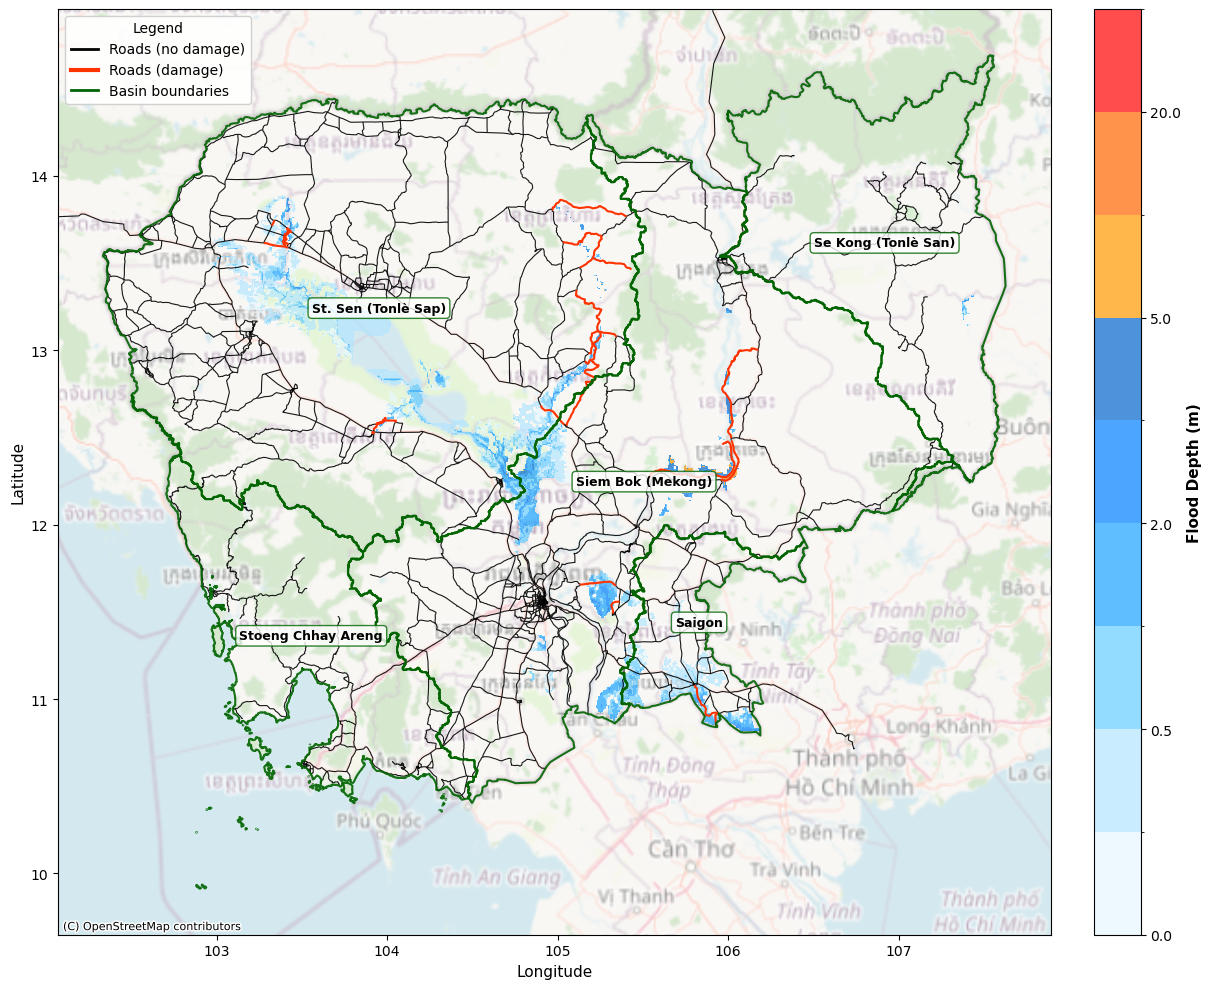

In [14]:
SCENARIOS['scenario_1'] = {'file': 'hazard_flood_2023-09-27.hdf5', 'title': ''}

# Load the hazard data for scenario_1
hazard_scenario_1, intensity_values_scenario_1, _, _ = load_and_process_hazard('scenario_1')
hazards_data['scenario_1'] = (hazard_scenario_1, intensity_values_scenario_1)
print(f"Processed scenario_1: max intensity {intensity_values_scenario_1.max():.2f}m")

# Create the single plot for scenario_1
fig_single_scenario_1 = create_single_plot(hazards_data, roads_gdf, basins_gdf, 
                                           scenario_name='scenario_1', 
                                           plot_type='combined', 
                                           show_disruption=False)
fig_single_scenario_1.savefig(FIGDIR / 'fig_direct_impacts.png', dpi=100, bbox_inches='tight')

### Cambodia Map Plot (Rivers + Roads)

In [15]:
def create_basins_rivers_roads_subplot(basins_gdf):
    """
    Create a subplot with two plots:
    - Left: Cambodia divided into 5 hydrobasins + main rivers (HydroRIVERS)
    - Right: Cambodia roads network (roads_edges_osm)
    """
    import fiona
    from matplotlib.lines import Line2D
    from matplotlib.patches import Patch
    
    # File paths
    rivers_gdb = "data/climada/HydroRIVERS_v10_as.gdb"
    roads_osm_file = "data/climada/roads_edges_osm.geojson"
    
    # Create figure with 2 subplots - larger figure for better readability
    fig, axes = plt.subplots(1, 2, figsize=(28, 14))
    
    # Get Cambodia bounds from basins (with some margin)
    bounds = basins_gdf.total_bounds  # [minx, miny, maxx, maxy]
    margin = 0.08  # Add 8% margin
    x_range = bounds[2] - bounds[0]
    y_range = bounds[3] - bounds[1]
    
    cambodia_bounds = [
        bounds[0] - margin * x_range,
        bounds[1] - margin * y_range,
        bounds[2] + margin * x_range,
        bounds[3] + margin * y_range
    ]
    
    # Set axis limits for both plots
    for ax in axes:
        ax.set_xlim(cambodia_bounds[0], cambodia_bounds[2])
        ax.set_ylim(cambodia_bounds[1], cambodia_bounds[3])
    
    # LEFT PLOT: Hydrobasins + Rivers

    ax_left = axes[0]
    
    # Add basemap
    try:
        ctx.add_basemap(ax_left, crs='EPSG:4326', source=ctx.providers.OpenStreetMap.Mapnik, zoom='auto', alpha=0.4)
    except Exception as e:
        print(f"basemap error (left): {e}")
    
    # Define colors for each basin (5 distinct, colorblind-friendly colors)
    basin_colors = ['#e41a1c', '#377eb8', '#4daf4a', '#984ea3', '#ff7f00']
    basin_names = basins_gdf['SUB_NAME'].tolist()
    
    # Plot basins with fill colors and thick borders
    for i, (idx, row) in enumerate(basins_gdf.iterrows()):
        color = basin_colors[i % len(basin_colors)]
        gpd.GeoDataFrame([row], crs=basins_gdf.crs).plot(
            ax=ax_left,
            color=color,
            alpha=0.4,
            edgecolor=color,
            linewidth=3
        )
    
    # Load and plot rivers
    try:
        layers = fiona.listlayers(rivers_gdb)
        print(f"HydroRIVERS layers available: {layers}")
        
        rivers_gdf = gpd.read_file(rivers_gdb, layer=layers[0])
        print(f"Total rivers loaded: {len(rivers_gdf)}")
        
        if 'ORD_STRA' in rivers_gdf.columns:
            print(f"Stream order values: {sorted(rivers_gdf['ORD_STRA'].dropna().unique())}")
        
        from shapely.geometry import box
        cambodia_box = box(cambodia_bounds[0], cambodia_bounds[1],
                           cambodia_bounds[2], cambodia_bounds[3])
        
        rivers_gdf = rivers_gdf[rivers_gdf.geometry.intersects(cambodia_box)]
        print(f"Rivers in Cambodia area: {len(rivers_gdf)}")
        
        if 'ORD_STRA' in rivers_gdf.columns:
            main_rivers = rivers_gdf[rivers_gdf['ORD_STRA'] >= 4].copy()
            print(f"Main rivers (order >= 4): {len(main_rivers)}")
            
            # Plot rivers with varying line width based on stream order
            for order in sorted(main_rivers['ORD_STRA'].unique(), reverse=True):
                rivers_subset = main_rivers[main_rivers['ORD_STRA'] == order]
                linewidth = 0.8 + (order - 4) * 0.8
                rivers_subset.plot(ax=ax_left, color='#08519c', linewidth=linewidth, alpha=0.85)
        else:
            rivers_gdf.plot(ax=ax_left, color='#08519c', linewidth=1.5, alpha=0.8)
            
    except Exception as e:
        print(f"Error loading rivers: {e}")
    
    # Add basin labels with LARGE, visible text
    for i, (idx, row) in enumerate(basins_gdf.iterrows()):
        centroid = row.geometry.centroid
        ax_left.annotate(
            row['SUB_NAME'],
            xy=(centroid.x, centroid.y),
            fontsize=22,
            fontweight='bold',
            ha='center',
            va='center',
            bbox=dict(
                boxstyle='round,pad=0.5',
                facecolor='white',
                edgecolor=basin_colors[i % len(basin_colors)],
                alpha=0.95,
                linewidth=2.5
            )
        )
    
    # Create legend for left plot
    legend_elements_left = [
        Line2D([0], [0], color='#08519c', lw=5, label='Main Rivers'),
    ]
    for i, name in enumerate(basin_names):
        legend_elements_left.append(
            Patch(facecolor=basin_colors[i % len(basin_colors)],
                  alpha=0.4, edgecolor=basin_colors[i % len(basin_colors)],
                  linewidth=2, label=name)
        )
    
    ax_left.legend(
        handles=legend_elements_left,
        loc='lower left',
        fontsize=18,
        framealpha=0.95,
        edgecolor='gray',
        title='Legend',
        title_fontsize=20
    )
    
    ax_left.set_title('Cambodia River Network', fontsize=30, fontweight='bold', pad=25)
    ax_left.set_xlabel('Longitude', fontsize=22, fontweight='bold')
    ax_left.set_ylabel('Latitude', fontsize=22, fontweight='bold')
    ax_left.tick_params(axis='both', labelsize=18)
    
    # RIGHT PLOT: Roads Network

    ax_right = axes[1]
    
    # Add basemap
    try:
        ctx.add_basemap(ax_right, crs='EPSG:4326', source=ctx.providers.OpenStreetMap.Mapnik, zoom='auto', alpha=0.4)
    except Exception as e:
        print(f"basemap error (right): {e}")
    
    # Load roads
    roads_osm = gpd.read_file(roads_osm_file)
    print(f"\nRoads loaded: {len(roads_osm)}")
    print(f"Roads columns: {list(roads_osm.columns)[:10]}")
    
    # Plot basin boundaries as reference (no fill)
    basins_gdf.boundary.plot(ax=ax_right, color='#555555', linewidth=2, alpha=0.7, linestyle='--')
    
    # Check for road type column and plot differently
    road_type_col = None
    for col in ['highway', 'road_type', 'type', 'fclass']:
        if col in roads_osm.columns:
            road_type_col = col
            break
    
    if road_type_col:
        print(f"Road types column: {road_type_col}")
        print(f"Road types: {roads_osm[road_type_col].unique()[:10]}")
        
        # Define road hierarchy with distinct colors
        road_styles = {
            'primary': {'color': '#d62728', 'width': 3.0, 'order': 1},
            'secondary': {'color': '#ff7f0e', 'width': 2.5, 'order': 2},
            'tertiary': {'color': '#bcbd22', 'width': 2.0, 'order': 3},
            'trunk': {'color': '#9467bd', 'width': 3.0, 'order': 0},
            'motorway': {'color': '#2ca02c', 'width': 3.5, 'order': 0},
        }
        
        # Plot other roads first (background)
        mask = ~roads_osm[road_type_col].str.contains('|'.join(road_styles.keys()), case=False, na=True)
        other_roads = roads_osm[mask]
        if len(other_roads) > 0:
            other_roads.plot(ax=ax_right, color='#888888', linewidth=0.6, alpha=0.4)
        
        # Plot roads by type (lower order roads first, then higher)
        for road_type, style in sorted(road_styles.items(), key=lambda x: -x[1]['order']):
            roads_type = roads_osm[roads_osm[road_type_col].str.contains(road_type, case=False, na=False)]
            if len(roads_type) > 0:
                roads_type.plot(ax=ax_right, color=style['color'], linewidth=style['width'], alpha=0.9)
        
        # Legend for roads
        legend_elements_right = [
            Line2D([0], [0], color='#2ca02c', lw=4, label='Motorway'),
            Line2D([0], [0], color='#9467bd', lw=3.5, label='Trunk'),
            Line2D([0], [0], color='#d62728', lw=3.5, label='Primary'),
            Line2D([0], [0], color='#ff7f0e', lw=3, label='Secondary'),
            Line2D([0], [0], color='#bcbd22', lw=2.5, label='Tertiary'),
            Line2D([0], [0], color='#888888', lw=1.5, label='Other Roads'),
            Line2D([0], [0], color='#555555', lw=2.5, linestyle='--', label='Basin Boundaries'),
        ]
    else:
        # Plot all roads with single style
        roads_osm.plot(ax=ax_right, color='#333333', linewidth=1, alpha=0.7)
        legend_elements_right = [
            Line2D([0], [0], color='#333333', lw=2.5, label='Roads'),
            Line2D([0], [0], color='#555555', lw=2.5, linestyle='--', label='Basin Boundaries'),
        ]
    
    ax_right.legend(
        handles=legend_elements_right,
        loc='lower left',
        fontsize=18,
        framealpha=0.95,
        edgecolor='gray',
        title='Legend',
        title_fontsize=20
    )
    
    ax_right.set_title('Cambodia Road Network', fontsize=30, fontweight='bold', pad=25)
    ax_right.set_xlabel('Longitude', fontsize=22, fontweight='bold')
    ax_right.set_ylabel('Latitude', fontsize=22, fontweight='bold')
    ax_right.tick_params(axis='both', labelsize=18)
    
    # Add subplot labels with large text
    ax_left.text(0.02, 0.98, '(a)', transform=ax_left.transAxes, fontsize=28, fontweight='bold',
                 va='top', ha='left', bbox=dict(boxstyle='round', facecolor='white', alpha=0.9, edgecolor='gray'))
    ax_right.text(0.02, 0.98, '(b)', transform=ax_right.transAxes, fontsize=28, fontweight='bold',
                  va='top', ha='left', bbox=dict(boxstyle='round', facecolor='white', alpha=0.9, edgecolor='gray'))
    
    plt.tight_layout()
    plt.subplots_adjust(wspace=0.06)
    
    # Save figure
    output_path = os.path.join(FIGURE_DIR, 'cambodia_basins_rivers_roads.png')
    plt.savefig(output_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"\nPlot saved: {output_path}")
    
    plt.show()
    return fig

HydroRIVERS layers available: ['HydroRIVERS_v10_as']
Total rivers loaded: 1428959
Stream order values: [1, 2, 3, 4, 5, 6, 7, 8, 9]
Rivers in Cambodia area: 35206
Main rivers (order >= 4): 4598

Roads loaded: 205902
Roads columns: ['code', 'fclass', 'name', 'ref', 'oneway', 'maxspeed', 'layer', 'bridge', 'tunnel', 'id']
Road types column: fclass
Road types: ['trunk' 'tertiary' 'unclassified' 'primary' 'pedestrian' 'footway' 'path'
 'service' 'track' 'secondary']

Plot saved: figures/generated/cambodia_basins_rivers_roads.png


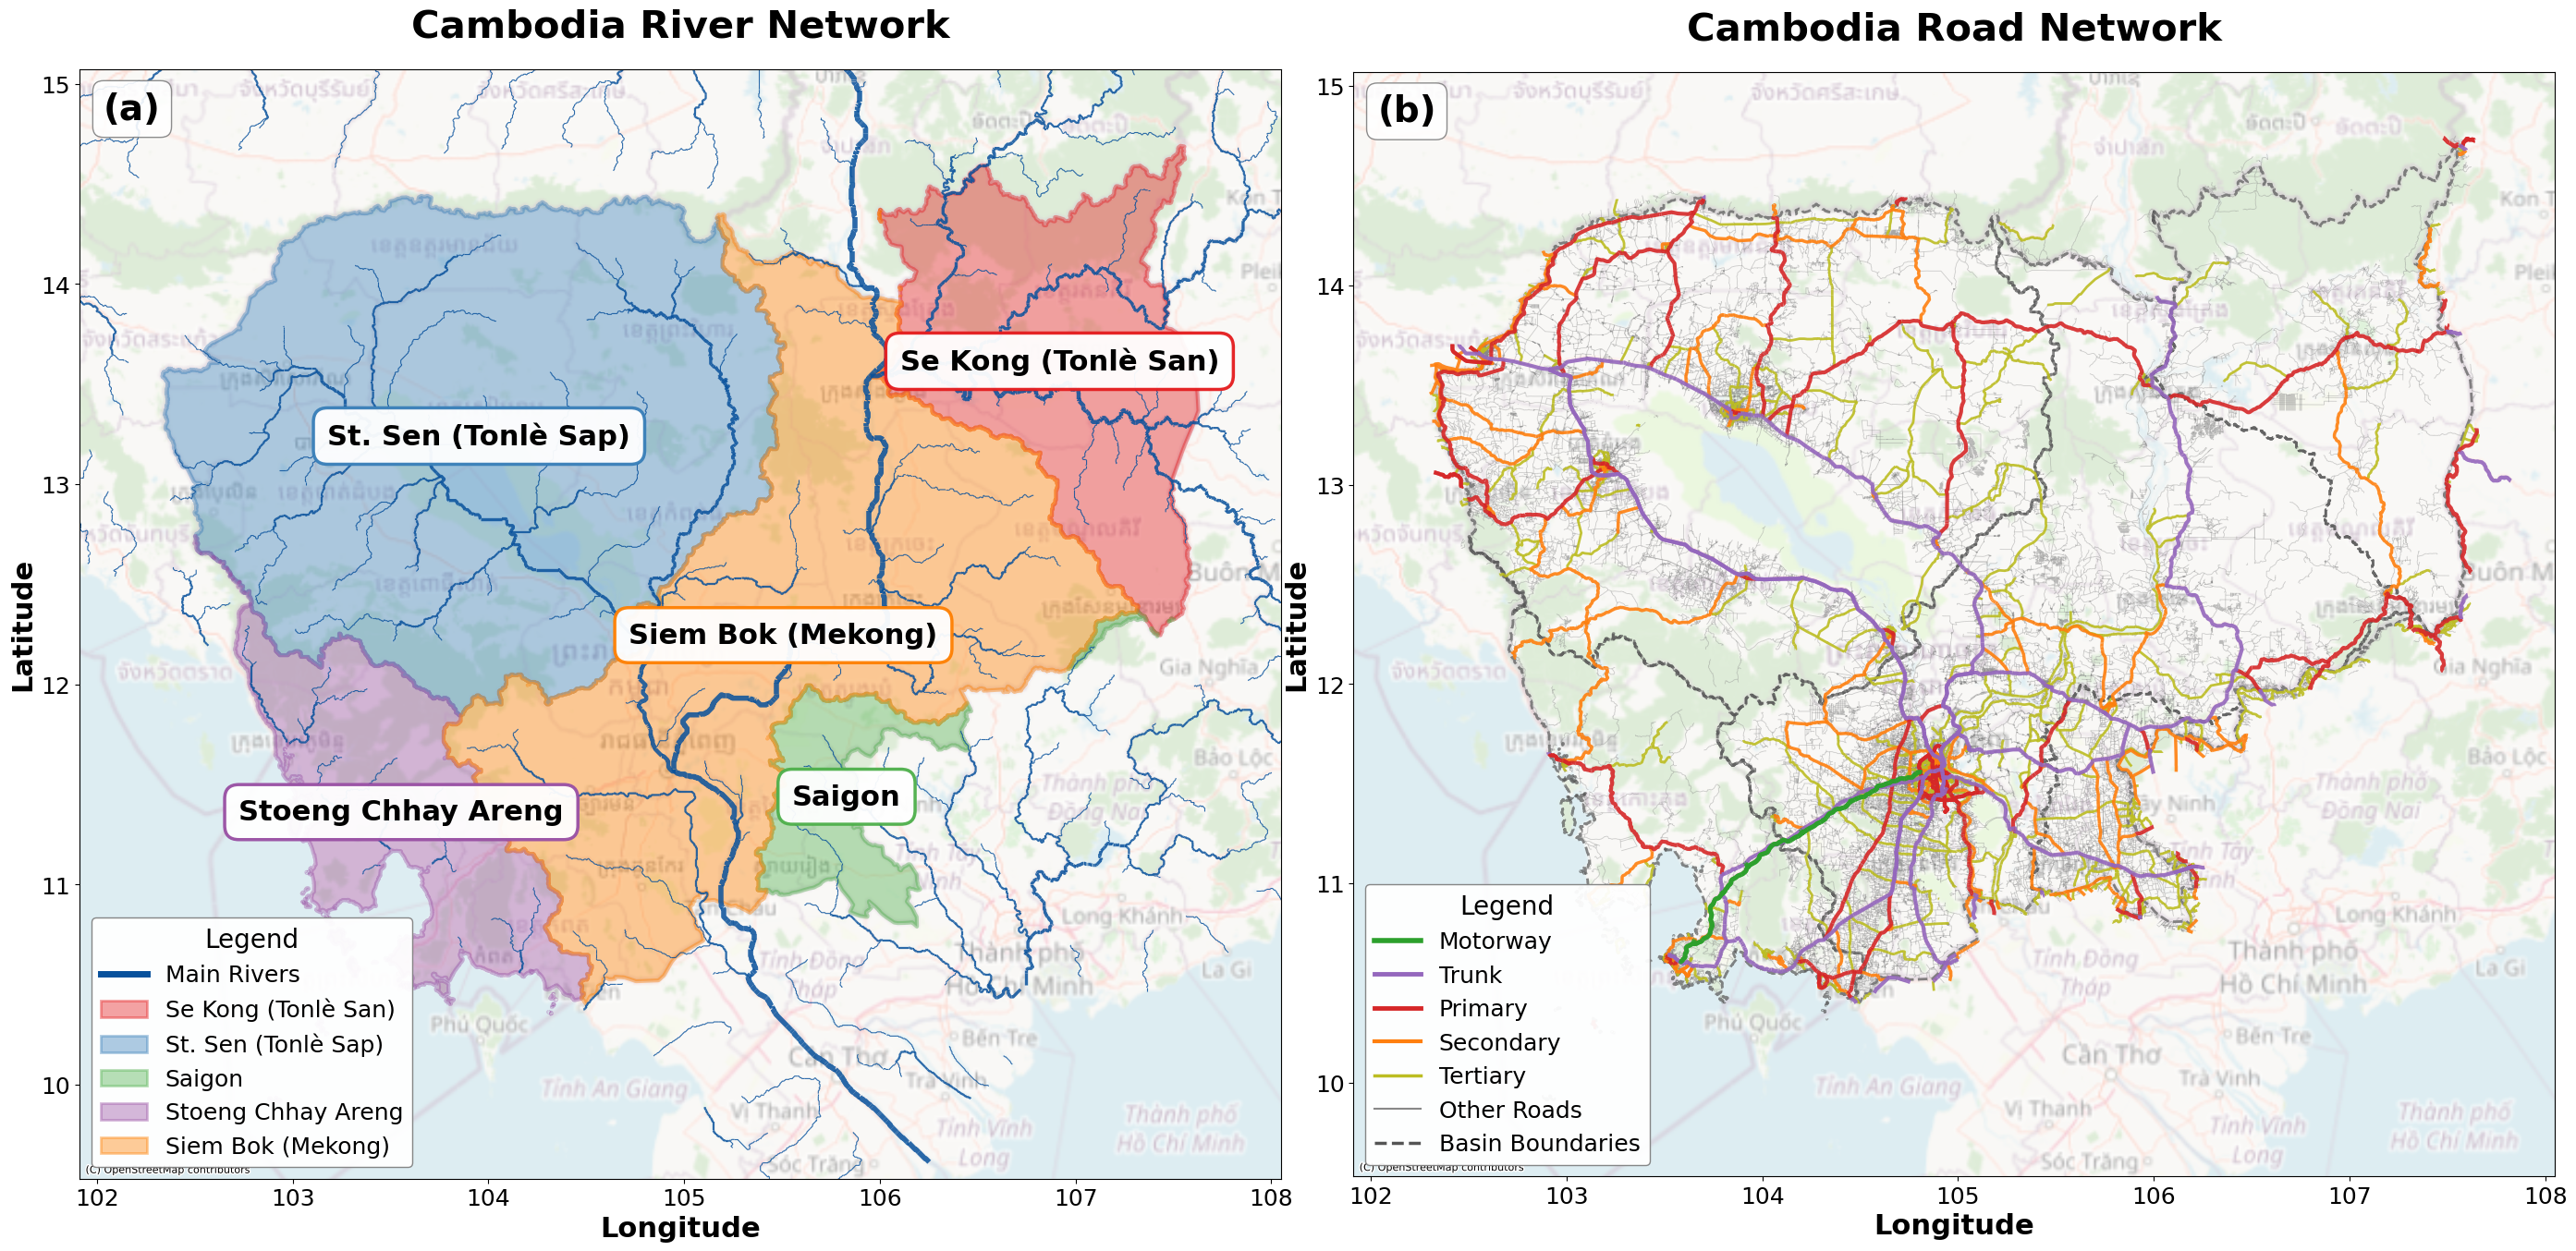

In [16]:
# Create the hydrobasins + rivers and roads subplot
fig_basins_rivers_roads = create_basins_rivers_roads_subplot(basins_gdf)

### Vulnerability Function

In [17]:
from climada.entity import ImpactFunc, ImpactFuncSet

In [18]:
class ImpFuncsRiverFlood():
    
    def __init__(self):
        self.tag = 'RF'
        self.dis = self.impf_dis()
        self.dmg = self.impf_dmg()
    
    # Disruption roads        
    def impf_dis(self):
        # adapted from Pregolato et al., 2017 - depth-disruption function for roads
        impf_dis = ImpactFunc() 
        impf_dis.id = 1
        impf_dis.haz_type = 'RF'
        impf_dis.name = 'Road disruption function (Pregnolato et al., 2017)'
        impf_dis.intensity_unit = 'water depth [m]'
        impf_dis.intensity = np.array([0, 0.299999, 0.3, 0.5, 1, 1.5, 2, 5, 6, 30.])
        impf_dis.mdd = np.array([0, 0, 1, 1, 1, 1, 1, 1, 1, 1])
        impf_dis.mdr = np.array([0, 0, 1, 1, 1, 1, 1, 1, 1, 1])
        impf_dis.paa = np.ones_like(impf_dis.intensity)
        impf_dis.check()
        return impf_dis
    
    # Damage roads
    def impf_dmg(self):
        # adapted from JRC RF vulnerability functions for Asia continent (infrastructures - roads)
        impf_dmg = ImpactFunc()
        impf_dmg.id = 1
        impf_dmg.haz_type = 'RF'
        impf_dmg.name = 'Vulnerability function for roads'
        impf_dmg.intensity_unit = 'water depth [m]'
        impf_dmg.intensity = np.array([0, 0.5, 1, 1.5, 2, 3, 4, 5, 6, 30.])
        impf_dmg.mdd = np.array([0.000, 0.2144, 0.3728, 0.6039, 0.7097, 0.8084, 
                                  0.8872, 0.9688, 1.0000, 1.0000])
        impf_dmg.mdr = np.array([0.000, 0.2144, 0.3728, 0.6039, 0.7097, 0.8084, 
                                  0.8872, 0.9688, 1.0000, 1.0000])
        impf_dmg.paa = np.ones_like(impf_dmg.intensity)
        impf_dmg.check()
        return impf_dmg

In [19]:
# Make ImpactFuncSet
imp_funcs = ImpFuncsRiverFlood()
impact_funcs_damage = ImpactFuncSet()
impact_funcs_disruption = ImpactFuncSet()

impact_funcs_disruption.append(imp_funcs.impf_dis())
impact_funcs_damage.append(imp_funcs.impf_dmg())

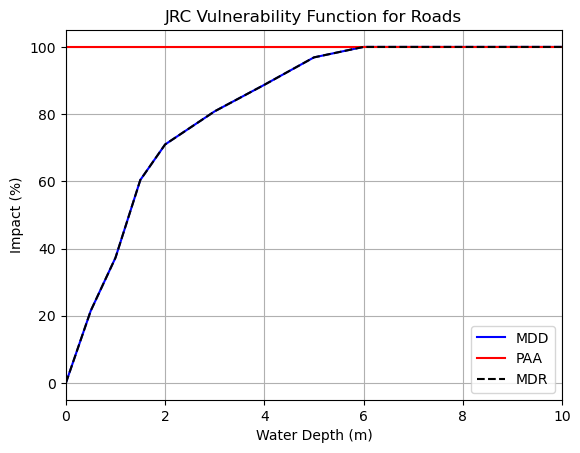

In [20]:
# Plot function
impf_dmg = imp_funcs.dmg
impf_dmg.plot()
plt.title('JRC Vulnerability Function for Roads')
plt.xlabel('Water Depth (m)')
plt.ylabel('Impact (%)')
plt.grid(True)
plt.xlim([0, 10])

plt.savefig(FIGDIR / 'jrc_vulnerability_function_roads.png', dpi=300, bbox_inches='tight')

plt.show()